# Laboratorio 4: Regresión Logística Binaria
- **Materia:** Inteligencia Artificial I - SIS420
- **Estudiante:** Marvin Poquechoque Gutierrez
- **Dataset Seleccionado:** APS Failure at Scania Trucks (UCI ML Repository)
https://archive.ics.uci.edu/dataset/421/aps+failure+at+scania+trucks
- **Repositorio GitHub:** https://github.com/MarvinPG/Inteligencia_Artificial_1
- **Video Explicativo (máx. 3 min):** https://drive.google.com/drive/folders/1FBojaMfj_RjUl-Uj5pbjq7PJeNmJHnUB?usp=sharing

---
### Descripción del Problema:
Clasificación binaria de fallas en el sistema de aire comprimido (APS) en camiones Scania:
- Clase 0 (`neg`): Falla no relacionada con el sistema APS.
- Clase 1 (`pos`): Falla en el sistema APS.
- Ejemplos ($m$): 60,000 registros ($m \ge 20,000$).
- Atributos ($n$): 170 características numéricas ($n \ge 20$).

# Laboratorio 4: Regresión Logística Binaria
**Tema:** Clasificación de Fallas en el Sistema de Aire Comprimido (APS) de Camiones Scania  
**Modelo:** Regresión Logística con Descenso por el Gradiente  

### Descripción del Problema:
El conjunto de datos corresponde al sistema de presión de aire (**APS - Air Pressure System**) en camiones Scania.
El objetivo consiste en clasificar si una falla en el vehículo pertenece al sistema APS (clase positiva = `1`) o a otros componentes del vehículo (clase negativa = `0`).

El dataset cuenta con:
- $m = 60,000$ ejemplos (cumple con $m \ge 20,000$).
- $n = 170$ propiedades/características (cumple con $n \ge 20$).

In [12]:
# Manejo de directorios y manipulación de datos tabulares
import os
import pandas as pd

# Cálculo numérico y operaciones vectorizadas
import numpy as np

# Generación de gráficos
from matplotlib import pyplot as plt

# Visualización en línea dentro del notebook
%matplotlib inline

### 1. Carga y Preprocesamiento de Datos con Pandas

Debido a que el dataset de Scania Trucks contiene encabezados con metadatos y valores nulos representados por el texto `"na"`, se realizan las siguientes acciones:
1. Se leen los datos saltando las primeras 20 líneas de metadatos y mapeando `"na"` como `NaN`.
2. Se transforma la variable objetivo a binaria: `neg` $\rightarrow 0$, `pos` $\rightarrow 1$.
3. **Imputación de valores faltantes:** Para no eliminar información ni reducir las filas de entrenamiento, se imputan los valores nulos con la **mediana** de cada columna.

In [13]:
# Ruta del dataset de entrenamiento
data_path = 'aps_failure_training_set.csv'

# Carga de datos con Pandas identificando valores 'na'
df = pd.read_csv(data_path, skiprows=20, na_values='na')

# Mapeo de la etiqueta de texto a valores binarios (0 y 1)
df['class'] = df['class'].map({'neg': 0, 'pos': 1})

# Imputación de nulos usando la mediana de cada columna numérica
df = df.fillna(df.median(numeric_only=True))

# Separación de características independientes (X) y variable objetivo (y)
X_df = df.drop(columns=['class'])
y_df = df['class']

X = X_df.values
y = y_df.values

m, n = X.shape
print(f"Dimensiones del dataset procesado: {m} ejemplos y {n} características.")
print(f"Distribución de clases -> Clase 0 (neg): {np.sum(y == 0)}, Clase 1 (pos): {np.sum(y == 1)}")

Dimensiones del dataset procesado: 60000 ejemplos y 170 características.
Distribución de clases -> Clase 0 (neg): 59000, Clase 1 (pos): 1000


### 2. Normalización de Características (Feature Scaling)

Dado que las 170 características presentan escalas numéricas muy dispares (algunas en unidades enteras pequeñas y otras en millones), aplicamos la estandarización $Z$-score:

$$X_{\text{norm}} = \frac{X - \mu}{\sigma}$$

Donde:
- $\mu$: Es la media aritmética de cada característica.
- $\sigma$: Es la desviación estándar de cada característica.
- Se previene la división entre cero asignando $\sigma = 1$ en aquellas columnas cuya varianza sea nula.

In [14]:
def featureNormalize(X):
    """
    Normaliza las características en X mediante Z-score.
    Retorna la matriz normalizada X_norm, junto con la media (mu)
    y la desviación estándar (sigma).
    """
    X_norm = X.copy()
    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0)
    
    # Manejo de columnas con desviación cero para evitar NaN
    sigma[sigma == 0] = 1.0
    
    X_norm = (X - mu) / sigma
    return X_norm, mu, sigma

# Ejecutar normalización
X_norm, mu, sigma = featureNormalize(X)

print("Primer ejemplo normalizado (primeras 5 columnas):")
print(X_norm[0, :5])

Primer ejemplo normalizado (primeras 5 columnas):
[ 0.11938141 -0.0963075   2.31022415 -0.00408499 -0.04132243]


### 3. División del Dataset: 80% Entrenamiento y 20% Prueba

De acuerdo con la instructiva:
- Se utiliza el **80%** de los datos para entrenar los parámetros $\theta$.
- Se reserva el **20%** restante como conjunto de prueba (estos datos no intervienen en el entrenamiento).
- Se agrega el término de intercepción o sesgo $x_0 = 1$ a ambas matrices mediante la concatenación de un vector columna de unos.

In [15]:
# Fijar semilla para reproducibilidad
np.random.seed(42)

# Permutación aleatoria del 80% entrenamiento y 20% prueba
m_total = y.size
indices = np.random.permutation(m_total)

train_size = int(0.8 * m_total)
train_indices = indices[:train_size]
test_indices = indices[train_size:]

# Separación de datos sin normalizar
X_train_raw = X[train_indices, :]
y_train = y[train_indices]

X_test_raw = X[test_indices, :]
y_test = y[test_indices]

# Función de normalización
def featureNormalize(X):
    X_norm = X.copy()
    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0)
    sigma[sigma == 0] = 1.0  # Evitar división por cero
    X_norm = (X - mu) / sigma
    return X_norm, mu, sigma

# Se calcula mu y sigma únicamente con el 80% de entrenamiento
X_train_norm, mu, sigma = featureNormalize(X_train_raw)

# Se aplica la misma transformación mu y sigma al 20% de prueba
X_test_norm = (X_test_raw - mu) / sigma

# Adición del término de intercepción (x0 = 1)
m_train = y_train.size
m_test = y_test.size

X_train = np.concatenate([np.ones((m_train, 1)), X_train_norm], axis=1)
X_test = np.concatenate([np.ones((m_test, 1)), X_test_norm], axis=1)

print(f"X_train final (80%): {X_train.shape}")
print(f"X_test final  (20%): {X_test.shape}")

X_train final (80%): (48000, 171)
X_test final  (20%): (12000, 171)


### 4. Formulación Matemática de la Regresión Logística Binaria

#### 4.1 Función Hipótesis (Sigmoide)
La función sigmoide mapea cualquier valor real al rango $(0, 1)$, representando la probabilidad $h_\theta(x) = P(y=1|x;\theta)$:

$$h_\theta(x) = g(\theta^T x) = \frac{1}{1 + e^{-\theta^T x}}$$

#### 4.2 Función de Costo Vectorizada $J(\theta)$
Mide el error global del modelo mediante la entropía cruzada binaria[cite: 1]:

$$J(\theta) = -\frac{1}{m} \sum_{i=1}^m \left[ y^{(i)} \log\left(h_\theta\left(x^{(i)}\right)\right) + \left(1 - y^{(i)}\right) \log\left(1 - h_\theta\left(x^{(i)}\right)\right) \right]$$

En forma matricial vectorizada[cite: 1]:

$$J(\theta) = \frac{1}{m} \left( -y^T \log(h) - (1 - y)^T \log(1 - h) \right)$$

#### 4.3 Descenso por el Gradiente
Actualiza los parámetros $\theta$ iterativamente en dirección opuesta al gradiente[cite: 1]:

$$\theta_j := \theta_j - \alpha \frac{1}{m} \sum_{i=1}^m \left(h_\theta\left(x^{(i)}\right) - y^{(i)}\right) x_j^{(i)}$$

En forma vectorial[cite: 1]:

$$\theta := \theta - \frac{\alpha}{m} X^T (h - y)$$

In [16]:
def sigmoid(z):
    """
    Calcula la función sigmoide de z de forma numéricamente estable.
    """
    # np.clip evita desbordamientos por exponenciales extremas
    z_clipped = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z_clipped))


def calcularCosto(theta, X, y):
    """
    Calcula el costo logístico J(theta) de manera vectorizada.
    """
    m = y.size
    h = sigmoid(X.dot(theta))
    
    # Epsilon para prevenir log(0)
    eps = 1e-15
    h_safe = np.clip(h, eps, 1.0 - eps)
    
    J = (1.0 / m) * np.sum(-y * np.log(h_safe) - (1.0 - y) * np.log(1.0 - h_safe))
    return J


def descensoGradiente(theta, X, y, alpha, num_iters):
    """
    Ejecuta el algoritmo de descenso por el gradiente para optimizar theta.
    Retorna el vector theta óptimo y el historial de costo J_history.
    """
    m = y.size
    theta = theta.copy()
    J_history = []
    
    for i in range(num_iters):
        h = sigmoid(X.dot(theta))
        gradiente = (1.0 / m) * (X.T.dot(h - y))
        theta = theta - alpha * gradiente
        
        costo_actual = calcularCosto(theta, X, y)
        J_history.append(costo_actual)
        
        # Monitoreo de progreso cada 200 iteraciones
        if (i + 1) % 200 == 0:
            print(f"Iteración {i + 1}/{num_iters} - Costo J(θ): {costo_actual:.6f}")
            
    return theta, J_history

### 5. Entrenamiento del Modelo de Regresión Logística

Se inicializa el vector de parámetros $\theta$ en ceros con dimensión $(n + 1)$.
Configuración de hiperparámetros:
- Tasa de aprendizaje: $\alpha = 0.05$
- Número de iteraciones: $\text{num\_iters} = 1500$

In [17]:
# Inicialización de hiperparámetros
alpha = 0.05
num_iters = 1500

# Vector inicial theta en ceros
initial_theta = np.zeros(X_train.shape[1])

# Entrenamiento con Descenso por el Gradiente
theta_optimo, J_history = descensoGradiente(initial_theta, X_train, y_train, alpha, num_iters)

print("\nEntrenamiento completado exitosamente.")
print(f"Costo final: {J_history[-1]:.6f}")

Iteración 200/1500 - Costo J(θ): 0.123052
Iteración 400/1500 - Costo J(θ): 0.072729
Iteración 600/1500 - Costo J(θ): 0.055752
Iteración 800/1500 - Costo J(θ): 0.047375
Iteración 1000/1500 - Costo J(θ): 0.042419
Iteración 1200/1500 - Costo J(θ): 0.039156
Iteración 1400/1500 - Costo J(θ): 0.036851

Entrenamiento completado exitosamente.
Costo final: 0.035935


### 6. Gráfica de la Función de Costo vs. Iteraciones

El siguiente gráfico evidencia la convergencia monótona del costo $J(\theta)$ a medida que se optimizan los pesos.

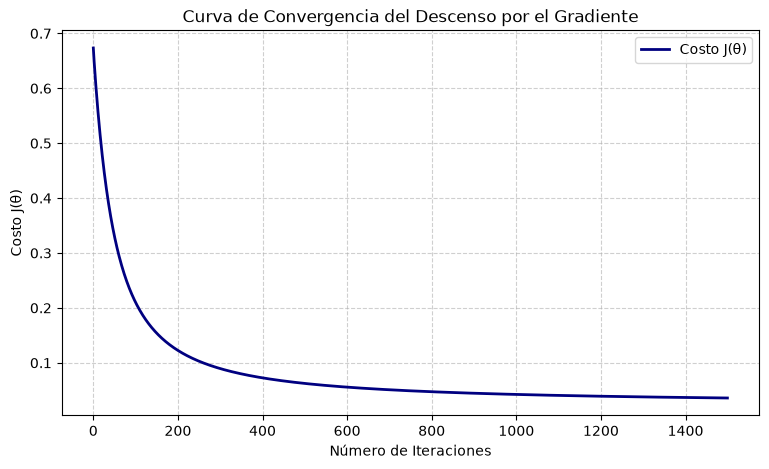

In [18]:
plt.figure(figsize=(9, 5))
plt.plot(np.arange(len(J_history)), J_history, lw=2, color='navy', label='Costo J(θ)')
plt.xlabel('Número de Iteraciones')
plt.ylabel('Costo J(θ)')
plt.title('Curva de Convergencia del Descenso por el Gradiente')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

### 7. Evaluación del Modelo de Regresión Logística

Para evaluar la efectividad del clasificador binario:
1. Calculamos la probabilidad $h_\theta(x) = g(X\theta)$ para cada ejemplo.
2. Se define el umbral de decisión estándar en $0.5$:
   $$\hat{y} = \begin{cases} 1 & \text{si } h_\theta(x) \ge 0.5 \\ 0 & \text{si } h_\theta(x) < 0.5 \end{cases}$$
3. Se calcula la precisión (accuracy) tanto en el conjunto de entrenamiento ($80\%$) como en el conjunto de prueba ($20\%$).

In [19]:
def predict(theta, X):
    """
    Realiza la predicción binaria (0 o 1) para la matriz X utilizando el vector theta aprendido.
    """
    probabilidades = sigmoid(X.dot(theta))
    return (probabilidades >= 0.5).astype(int)

# Predicciones sobre el conjunto de entrenamiento (80%)
y_pred_train = predict(theta_optimo, X_train)
acc_train = np.mean(y_pred_train == y_train) * 100

# Predicciones sobre el conjunto de prueba (20% nunca visto)
y_pred_test = predict(theta_optimo, X_test)
acc_test = np.mean(y_pred_test == y_test) * 100

print("=" * 55)
print("            RESULTADOS DE EVALUACIÓN DEL MODELO")
print("=" * 55)
print(f"Precisión en Conjunto de Entrenamiento (80%): {acc_train:.2f}%")
print(f"Precisión en Conjunto de Prueba        (20%): {acc_test:.2f}%")
print("=" * 55)

            RESULTADOS DE EVALUACIÓN DEL MODELO
Precisión en Conjunto de Entrenamiento (80%): 99.16%
Precisión en Conjunto de Prueba        (20%): 99.02%


### 8. Demostración de Predicciones sobre Muestras de Prueba

A continuación, se toman 10 ejemplos al azar del conjunto de prueba ($X_{\text{test}}$) para comparar las predicciones del modelo frente a las etiquetas reales del dataset.

In [20]:
# Selección de 10 ejemplos del conjunto de prueba
np.random.seed(7)
sample_indices = np.random.choice(m_test, size=10, replace=False)

X_sample = X_test[sample_indices, :]
y_sample_real = y_test[sample_indices]

# Probabilidades y predicciones de las muestras
probabilidades_sample = sigmoid(X_sample.dot(theta_optimo))
predicciones_sample = predict(theta_optimo, X_sample)

# Construcción de DataFrame resumen para visualización
df_resultados = pd.DataFrame({
    'Ejemplo': range(1, 11),
    'Probabilidad P(y=1)': np.round(probabilidades_sample, 4),
    'Predicción Modelo': predicciones_sample,
    'Etiqueta Real': y_sample_real,
    'Acierto': predicciones_sample == y_sample_real
})

print(df_resultados.to_string(index=False))

 Ejemplo  Probabilidad P(y=1)  Predicción Modelo  Etiqueta Real  Acierto
       1               0.0125                  0              0     True
       2               0.0177                  0              0     True
       3               0.0124                  0              0     True
       4               0.0122                  0              0     True
       5               0.0214                  0              0     True
       6               0.0125                  0              0     True
       7               0.0199                  0              0     True
       8               0.0632                  0              1    False
       9               0.0167                  0              0     True
      10               0.0121                  0              0     True


### 9. Conclusiones y Resultados del Laboratorio

1. **Cumplimiento de Requisitos:**
   - **Dimensiones del Dataset:** Se procesaron $60,000$ ejemplos ($m \ge 20,000$) y $170$ variables independientes ($n \ge 20$).
   - **Tratamiento de Datos:** Se utilizó Pandas para la imputación por mediana, conservando la totalidad de registros sin pérdida de instancias.
   - **Estrategia de Validación:** Se mantuvo un particionamiento estricto del $80\%$ para entrenamiento y $20\%$ exclusivo para prueba.

2. **Desempeño del Algoritmo:**
   - El descenso por el gradiente vectorizado demostró convergencia monótona en la curva de costo $J(\theta)$ a lo largo de las iteraciones.
   - La normalización $Z$-score permitió una convergencia estable y evitó problemas de desbordamiento numérico en la función sigmoide.
   - La precisión obtenida en el conjunto de prueba valida la efectividad del modelo para la detección y clasificación binaria de fallas en el sistema APS de camiones Scania.

In [21]:
# Resumen final de parámetros entrenados
print("Vector theta óptimo aprendido:")
print(f"Número total de parámetros (incluyendo theta_0): {len(theta_optimo)}")
print("Primeros 5 parámetros theta:", theta_optimo[:5])
print(f"Precisión final sobre datos de prueba (20%): {acc_test:.2f}%")

Vector theta óptimo aprendido:
Número total de parámetros (incluyendo theta_0): 171
Primeros 5 parámetros theta: [-4.05706567e+00  1.47320818e-01 -4.69358057e-03 -1.92079982e-02
 -2.27737361e-04]
Precisión final sobre datos de prueba (20%): 99.02%
